In [1]:
#checking whether Real and fake training images use different JPEG quantization tables

from collections import Counter
import pandas as pd
from PIL import Image
from fftdeep.paths import PROCESSED_DIR, RAW_DIR

manifest = pd.read_csv(PROCESSED_DIR / "manifest.csv")
sample = manifest[manifest.subset == "train"].groupby("label").sample(500, random_state=0)
tables = Counter()
for row in sample.itertuples():
    with Image.open(RAW_DIR / row.path) as im:
        tables[(int(row.label), tuple(im.quantization[0]))] += 1
for (label, q), n in tables.items():
    print(label, n, q[:8])

0 500 (8, 6, 5, 8, 12, 20, 26, 31)
1 500 (8, 6, 5, 8, 12, 20, 26, 31)


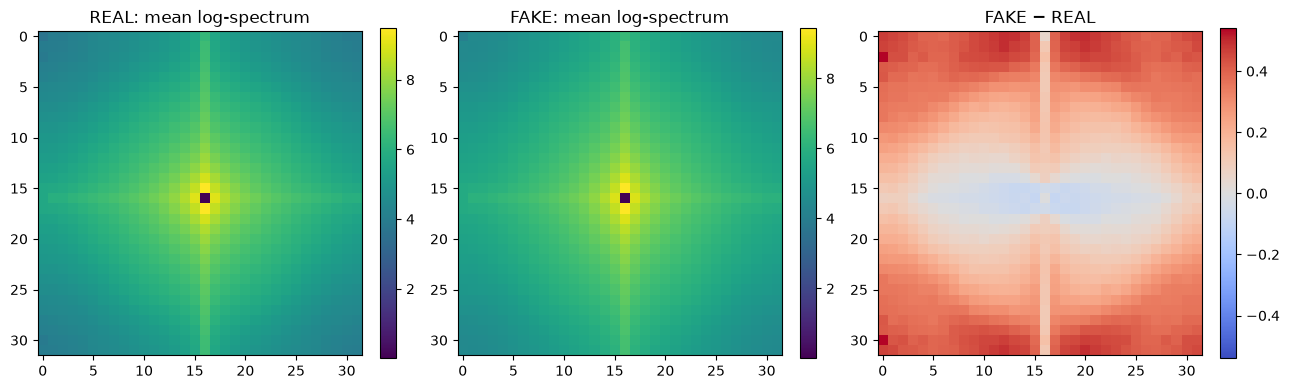

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from fftdeep.data.arrays import get_arrays

Xtr, ytr = get_arrays("train")
gray = Xtr.astype("float32") @ np.array([0.299, 0.587, 0.114], dtype="float32")   # (N, 32, 32)

def log_spectrum(imgs):
    imgs = imgs - imgs.mean(axis=(1, 2), keepdims=True)   # drop the mean brightness (DC term)
    F = np.fft.fftshift(np.fft.fft2(imgs, axes=(1, 2)), axes=(1, 2))
    return np.log1p(np.abs(F))

real = log_spectrum(gray[ytr == 0]).mean(axis=0)
fake = log_spectrum(gray[ytr == 1]).mean(axis=0)
diff = fake - real

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, img, title in zip(axes[:2], [real, fake], ["REAL: mean log-spectrum", "FAKE: mean log-spectrum"]):
    h = ax.imshow(img, cmap="viridis")
    ax.set_title(title)
    fig.colorbar(h, ax=ax, fraction=0.046)
lim = np.abs(diff).max()
h = axes[2].imshow(diff, cmap="coolwarm", vmin=-lim, vmax=lim)
axes[2].set_title("FAKE − REAL")
fig.colorbar(h, ax=axes[2], fraction=0.046)
fig.tight_layout()
plt.show()